In [2]:
import os
import time
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.init as init
from torch.autograd import grad

def set_random_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True
    torch.backends.cudnn.enabled = True
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print(f"随机种子设置为: {seed}")

set_random_seed(42)
torch.set_default_dtype(torch.float32)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

随机种子设置为: 42
Using device: cuda


In [2]:
def get_physical_parameters():
    params = {
        "rho": 960.0,
        "mu": 8.526e-4,
        "dp": 1e-4,
        "L": 0.02,
        "p_outlet": 1e5,
        "v_inlet": 1.0 / 960.0,
        # 双区域孔隙率
        "eps1": 0.2,   # 圆外区域
        "eps2": 0.5,   # 圆内区域
        # 圆形界面几何
        "xc": 0.01,
        "yc": 0.01,
        "R": 0.003,
        # 特征尺度
        "mu_0": 8.526e-4,
        "k_0": 1e-12,
        "V_0": 1e-3,
        "L_0": 0.02,
    }
    params["P_0"] = (params["L_0"] * params["mu_0"] * params["V_0"]) / params["k_0"]
    return params


def permeability(eps, dp):
    """Ergun 关系：K = dp^2 * eps^3 / [150 (1-eps)^2]"""
    return (dp ** 2) * (eps ** 3) / (150.0 * (1.0 - eps) ** 2)


params = get_physical_parameters()
LAMBDA_GAMMA = 1.0

In [3]:
class SimplePINN(nn.Module):
    def __init__(self, in_dim=2, out_dim=3, hidden_dim=20, num_hidden_layers=6):
        super().__init__()
        layers = [nn.Linear(in_dim, hidden_dim), nn.Tanh()]
        for _ in range(num_hidden_layers - 1):
            layers += [nn.Linear(hidden_dim, hidden_dim), nn.Tanh()]
        layers.append(nn.Linear(hidden_dim, out_dim))
        self.net = nn.Sequential(*layers)
        self._init_weights()

    def _init_weights(self):
        for i, m in enumerate(self.net):
            if isinstance(m, nn.Linear):
                gain = init.calculate_gain("tanh") if i + 1 < len(self.net) and isinstance(self.net[i + 1], nn.Tanh) else 1.0
                init.xavier_uniform_(m.weight, gain=gain)
                init.zeros_(m.bias)

    def forward(self, x):
        return self.net(x)


net_out = SimplePINN().to(device)   # 圆外区域网络
net_in = SimplePINN().to(device)    # 圆内区域网络

In [4]:
def phys_to_star(x_phys, y_phys, params, device):
    """物理坐标 [0,L] 转无量纲坐标 [-1,1]。"""
    L = params["L"]
    x_star = np.asarray(x_phys, dtype=np.float64) / L * 2.0 - 1.0
    y_star = np.asarray(y_phys, dtype=np.float64) / L * 2.0 - 1.0
    x_star = torch.tensor(x_star, dtype=torch.get_default_dtype(), device=device).view(-1, 1)
    y_star = torch.tensor(y_star, dtype=torch.get_default_dtype(), device=device).view(-1, 1)
    return x_star, y_star

def star_to_phys(coords_star, params):
    L = params["L"]
    x_phys = (coords_star[:, 0] + 1.0) * 0.5 * L
    y_phys = (coords_star[:, 1] + 1.0) * 0.5 * L
    return x_phys, y_phys

In [5]:
def make_cell(x_min, x_max, y_min, y_max, level=0, region=""):
    return {
        "x_min": float(x_min), "x_max": float(x_max),
        "y_min": float(y_min), "y_max": float(y_max),
        "level": int(level), "region": region,
        "eta": 0.0, "eta2": 0.0,
        "is_interface": False, #默认是false
    }

def point_region_by_circle(x, y, params):
    "判断点在圆内还是圆外"
    r2 = (x - params["xc"]) ** 2 + (y - params["yc"]) ** 2
    return "in" if r2 < params["R"] ** 2 else "out"

def classify_cell_by_center(cell, params):
    "取中心点"
    cx = 0.5 * (cell["x_min"] + cell["x_max"])
    cy = 0.5 * (cell["y_min"] + cell["y_max"])
    return point_region_by_circle(cx, cy, params)

def cell_size(cell):
    "找网格的长度"
    return max(cell["x_max"] - cell["x_min"], cell["y_max"] - cell["y_min"])


def cell_area(cell):
    "面积"
    return (cell["x_max"] - cell["x_min"]) * (cell["y_max"] - cell["y_min"])


def build_initial_cells(params, nx0=10, ny0=10):
    "建立初始网格"
    L = params["L"]
    dx = L / nx0
    dy = L / ny0
    cells = []
    for i in range(nx0):
        for j in range(ny0):
            x0, x1 = i * dx, (i + 1) * dx
            y0, y1 = j * dy, (j + 1) * dy
            c = make_cell(x0, x1, y0, y1, level=0)
            c["region"] = classify_cell_by_center(c, params)
            cells.append(c)
    return cells


def split_cell(cell, params=None):
    "分裂单元，并且归属到内还是外"
    x0, x1 = cell["x_min"], cell["x_max"]
    y0, y1 = cell["y_min"], cell["y_max"]
    xm, ym = 0.5 * (x0 + x1), 0.5 * (y0 + y1)
    boxes = [
        (x0, xm, y0, ym), (xm, x1, y0, ym),
        (x0, xm, ym, y1), (xm, x1, ym, y1),
    ]
    children = []
    for xa, xb, ya, yb in boxes:
        cc = make_cell(xa, xb, ya, yb, level=cell["level"] + 1)
        if params is not None:
            cc["region"] = classify_cell_by_center(cc, params)
        children.append(cc)
    return children

In [6]:
def cell_intersects_circle(cell, params, tol=1e-14):
    """判断 cell 是否被圆形界面穿过。是否是界面网格"""
    x0, x1 = cell["x_min"], cell["x_max"]
    y0, y1 = cell["y_min"], cell["y_max"]
    xc, yc, R = params["xc"], params["yc"], params["R"]

    x_closest = min(max(xc, x0), x1)
    y_closest = min(max(yc, y0), y1)
    dmin = math.hypot(x_closest - xc, y_closest - yc)

    corners = [(x0, y0), (x1, y0), (x0, y1), (x1, y1)]
    dmax = max(math.hypot(x - xc, y - yc) for x, y in corners)
    return (dmin <= R + tol) and (dmax >= R - tol)


def circle_cell_intersections(cell, params, tol=1e-12):
    """求圆形界面和矩形 cell 边界的交点。"""
    x0, x1 = cell["x_min"], cell["x_max"]
    y0, y1 = cell["y_min"], cell["y_max"]
    xc, yc, R = params["xc"], params["yc"], params["R"]
    pts = []

    for x in (x0, x1):
        val = R ** 2 - (x - xc) ** 2
        if val >= -tol:
            dy = math.sqrt(max(val, 0.0))
            for y in (yc - dy, yc + dy):
                if y0 - tol <= y <= y1 + tol:
                    pts.append((x, min(max(y, y0), y1)))

    for y in (y0, y1):
        val = R ** 2 - (y - yc) ** 2
        if val >= -tol:
            dx = math.sqrt(max(val, 0.0))
            for x in (xc - dx, xc + dx):
                if x0 - tol <= x <= x1 + tol:
                    pts.append((min(max(x, x0), x1), y))

    unique = []  #去重 
    for p in pts:
        if not any((p[0] - q[0]) ** 2 + (p[1] - q[1]) ** 2 < tol ** 2 for q in unique):
            unique.append(p)
    return unique

In [7]:
def local_interface_geometry(cell, params):

    if not cell_intersects_circle(cell, params): 
        return False, None, 0.0, None  #不是界面单元；无界面中点；界面长度为 0；无界面法向量

    pts = circle_cell_intersections(cell, params)
    if len(pts) < 2:  #因为算圆弧的话，就是需要2个点啊
        return False, None, 0.0, None   #该单元格不是有效界面单元，不存在圆弧中点 p_if，界面长度为 0，没有界面单位法向量 normal

    max_d2 = -1.0
    A, B = pts[0], pts[1]
    for i in range(len(pts)):
        for j in range(i + 1, len(pts)):
            d2 = (pts[i][0] - pts[j][0]) ** 2 + (pts[i][1] - pts[j][1]) ** 2
            if d2 > max_d2:
                max_d2 = d2
                A, B = pts[i], pts[j]  ##返回的是合格的交点

    length_if = math.sqrt(max_d2)
    if length_if < 1e-14:
        return False, None, 0.0, None

    xc, yc, R = params["xc"], params["yc"], params["R"]
    ta = math.atan2(A[1] - yc, A[0] - xc)  #极角
    tb = math.atan2(B[1] - yc, B[0] - xc)
    diff = (tb - ta + math.pi) % (2.0 * math.pi) - math.pi
    tm = ta + 0.5 * diff

    p_if = (xc + R * math.cos(tm), yc + R * math.sin(tm))  #中点坐标
    normal = (math.cos(tm), math.sin(tm))  #外法线
    return True, p_if, length_if, normal

In [8]:
def estimate_area_fractions_by_sampling(cell, params, n_side=7, min_frac=1e-6):
    """
    用辅助撒点估计界面 cell 内两侧面积比例。
    """
    x0, x1 = cell["x_min"], cell["x_max"]
    y0, y1 = cell["y_min"], cell["y_max"]
    xs = np.linspace(x0 + 0.5 * (x1 - x0) / n_side, x1 - 0.5 * (x1 - x0) / n_side, n_side)
    ys = np.linspace(y0 + 0.5 * (y1 - y0) / n_side, y1 - 0.5 * (y1 - y0) / n_side, n_side)

    n_in = 0
    n_total = n_side * n_side
    for x in xs:
        for y in ys:
            if point_region_by_circle(x, y, params) == "in":
                n_in += 1

    frac_in = n_in / n_total
    frac_out = 1.0 - frac_in

    # 防止极小切割区域被采样漏掉，给一个极小正权重
    frac_in = max(frac_in, min_frac)
    frac_out = max(frac_out, min_frac)
    s = frac_in + frac_out
    return frac_out / s, frac_in / s


def find_point_in_cell_region(cell, params, desired_region, p_if=None, normal=None):
    """在界面 cell 内找一个属于 desired_region 的 PDE 点。"""
    x0, x1 = cell["x_min"], cell["x_max"]
    y0, y1 = cell["y_min"], cell["y_max"]
    h = cell_size(cell)
    eps = 1e-12 * params["L"]

    # 优先从界面点沿法向两侧取点
    if p_if is not None and normal is not None:
        sign = 1.0 if desired_region == "out" else -1.0
        for fac in (0.25, 0.18, 0.12, 0.08, 0.04, 0.02, 0.01, 0.005, 0.001, 1e-4, 1e-5, 1e-6):
            x = p_if[0] + sign * fac * h * normal[0]
            y = p_if[1] + sign * fac * h * normal[1]
            if x0 + eps <= x <= x1 - eps and y0 + eps <= y <= y1 - eps:
                if point_region_by_circle(x, y, params) == desired_region:
                    return x, y

    # 兜底：在 cell 内找一个对应区域点
    xs = np.linspace(x0 + 0.15 * (x1 - x0), x1 - 0.15 * (x1 - x0), 5)
    ys = np.linspace(y0 + 0.15 * (y1 - y0), y1 - 0.15 * (y1 - y0), 5)
    best = None
    best_dist = -1.0
    for x in xs:
        for y in ys:
            if point_region_by_circle(x, y, params) == desired_region:
                dist = abs(math.hypot(x - params["xc"], y - params["yc"]) - params["R"])
                if dist > best_dist:
                    best = (x, y)
                    best_dist = dist
    if best is not None:
        return best

    # 几何保证型兜底：不再错误返回单元中心。
    # q_in 为矩形中距圆心最近的点，q_out 为距圆心最远的角点。
    # 对真正的切割单元，二者分别位于圆内和圆外。
    q_in = np.array([
        min(max(params["xc"], x0), x1),
        min(max(params["yc"], y0), y1),
    ], dtype=np.float64)

    corners = np.array([
        [x0, y0], [x1, y0], [x0, y1], [x1, y1]
    ], dtype=np.float64)
    circle_center = np.array(
        [params["xc"], params["yc"]], dtype=np.float64
    )
    q_out = corners[
        np.argmax(np.sum((corners - circle_center) ** 2, axis=1))
    ]

    def signed_circle_value(point):
        return (
            (point[0] - params["xc"]) ** 2
            + (point[1] - params["yc"]) ** 2
            - params["R"] ** 2
        )

    value_in = signed_circle_value(q_in)
    value_out = signed_circle_value(q_out)
    if not (value_in < 0.0 and value_out > 0.0):
        raise RuntimeError(
            f"无法在圆形切割单元中构造两侧见证点: "
            f"value_in={value_in:.12e}, value_out={value_out:.12e}, "
            f"cell={cell}"
        )

    left = q_in.copy()    # 始终位于圆内
    right = q_out.copy()  # 始终位于圆外
    for _ in range(80):
        middle = 0.5 * (left + right)
        if signed_circle_value(middle) < 0.0:
            left = middle
        else:
            right = middle

    point = (
        0.5 * (q_in + left)
        if desired_region == "in"
        else 0.5 * (q_out + right)
    )
    return float(point[0]), float(point[1])

In [9]:
def sample_points_from_matched_cells(cells, params, device):
    out_x, out_y = [], []
    in_x, in_y = [], []
    if_x, if_y, if_theta = [], [], []

    out_cells_plot, in_cells_plot = [], []
    n_interface = 0

    for c in cells:
        c["region"] = classify_cell_by_center(c, params)
        if c["region"] == "in":
            in_cells_plot.append(c)
        else:
            out_cells_plot.append(c)

        is_if, p_if, length_if, normal = local_interface_geometry(c, params)
        c["is_interface"] = bool(is_if)
        c["interface_length"] = float(length_if)

        if is_if:
            n_interface += 1
            if_x.append(p_if[0])
            if_y.append(p_if[1])
            if_theta.append(math.atan2(p_if[1] - params["yc"], p_if[0] - params["xc"]))

            p_out = find_point_in_cell_region(c, params, "out", p_if=p_if, normal=normal)
            p_in = find_point_in_cell_region(c, params, "in", p_if=p_if, normal=normal)
            out_x.append(p_out[0]); out_y.append(p_out[1])
            in_x.append(p_in[0]); in_y.append(p_in[1])
        else:
            cx = 0.5 * (c["x_min"] + c["x_max"])
            cy = 0.5 * (c["y_min"] + c["y_max"])
            if c["region"] == "in":
                in_x.append(cx); in_y.append(cy)
            else:
                out_x.append(cx); out_y.append(cy)

    out_x = np.asarray(out_x, dtype=np.float64); out_y = np.asarray(out_y, dtype=np.float64)
    in_x = np.asarray(in_x, dtype=np.float64); in_y = np.asarray(in_y, dtype=np.float64)
    if_x = np.asarray(if_x, dtype=np.float64); if_y = np.asarray(if_y, dtype=np.float64)
    if_theta = np.asarray(if_theta, dtype=np.float64)

    # 强制验证界面单元的两侧 PDE 点，不允许错分点进入正问题损失。
    out_r2 = (out_x - params["xc"]) ** 2 + (out_y - params["yc"]) ** 2
    in_r2 = (in_x - params["xc"]) ** 2 + (in_y - params["yc"]) ** 2
    wrong_out = int(np.sum(out_r2 < params["R"] ** 2))
    wrong_in = int(np.sum(in_r2 >= params["R"] ** 2))
    if wrong_out or wrong_in:
        raise RuntimeError(
            f"圆形正问题采样分域失败: wrong_out={wrong_out}, wrong_in={wrong_in}"
        )

    x_out, y_out = phys_to_star(out_x, out_y, params, device)
    x_in, y_in = phys_to_star(in_x, in_y, params, device)
    x_if, y_if = phys_to_star(if_x, if_y, params, device)

    out_sample = {"x": x_out, "y": y_out, "x_phys": out_x, "y_phys": out_y}
    in_sample = {"x": x_in, "y": y_in, "x_phys": in_x, "y_phys": in_y}
    interface_sample = {"theta": if_theta, "x": x_if, "y": y_if, "x_phys": if_x, "y_phys": if_y}

    print("========== 基于界面 cell 的匹配采样完成 ==========")
    print(f"leaf cell 数量: {len(cells)}")
    print(f"界面 cell 数量: {n_interface}")
    print(f"孔外 PDE 点数量: {len(out_x)}")
    print(f"孔内 PDE 点数量: {len(in_x)}")
    print(f"界面点数量: {len(if_x)}")
    print("==============================================")
    return out_sample, in_sample, interface_sample, out_cells_plot, in_cells_plot

In [10]:
def plot_cells(ax, cells, edgecolor="0.35", linewidth=0.4, alpha=0.8):
    for c in cells:
        x0, x1 = c["x_min"], c["x_max"]
        y0, y1 = c["y_min"], c["y_max"]
        ax.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color=edgecolor, linewidth=linewidth, alpha=alpha)


def plot_adaptive_sampling_circle(out_cells, in_cells, out_sample, in_sample, interface_sample, params,
                                  title="Adaptive sampling mesh", save_path=None):
    L = params["L"]
    fig, ax = plt.subplots(figsize=(7, 7))
    plot_cells(ax, out_cells, edgecolor="0.25", linewidth=0.35, alpha=0.65)
    plot_cells(ax, in_cells, edgecolor="0.25", linewidth=0.35, alpha=0.85)

    ax.scatter(out_sample["x_phys"], out_sample["y_phys"], s=4, alpha=0.45, label="PDE points outside")
    ax.scatter(in_sample["x_phys"], in_sample["y_phys"], s=4, alpha=0.55, label="PDE points inside")
    ax.scatter(interface_sample["x_phys"], interface_sample["y_phys"], s=9, alpha=0.85, marker="x", label="Interface points")
    ax.plot([0, L, L, 0, 0], [0, 0, L, L, 0], "k-", linewidth=1.2)
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(False)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"采样网格图已保存: {save_path}")
    plt.show()


def export_mesh_data_to_folder(save_root, round_label, out_cells, in_cells, out_sample, in_sample, interface_sample):
    sub_dir = os.path.join(save_root, round_label)
    os.makedirs(sub_dir, exist_ok=True)

    pd.DataFrame({"x(m)": out_sample["x_phys"], "y(m)": out_sample["y_phys"]}).to_csv(os.path.join(sub_dir, "01_PDE_outside.csv"), index=False)
    pd.DataFrame({"x(m)": in_sample["x_phys"], "y(m)": in_sample["y_phys"]}).to_csv(os.path.join(sub_dir, "02_PDE_inside.csv"), index=False)
    pd.DataFrame({"x(m)": interface_sample["x_phys"], "y(m)": interface_sample["y_phys"]}).to_csv(os.path.join(sub_dir, "03_interface_points.csv"), index=False)

    grid_lines = []
    for c in out_cells + in_cells:
        x0, x1 = c["x_min"], c["x_max"]
        y0, y1 = c["y_min"], c["y_max"]
        grid_lines += [[x0, y0], [x1, y0], [x1, y1], [x0, y1], [x0, y0], [np.nan, np.nan]]
    arr = np.array(grid_lines)
    pd.DataFrame({"x_grid(m)": arr[:, 0], "y_grid(m)": arr[:, 1]}).to_csv(os.path.join(sub_dir, "04_mesh_grid_lines.csv"), index=False)
    print(f"✅ 网格数据导出完成 | 文件夹：{sub_dir}")
    return sub_dir

In [11]:
def gradients(y, x):
    return grad(y, x, grad_outputs=torch.ones_like(y), create_graph=True, retain_graph=True)[0]


def forward_with_hard_bc(net, coords, params):
    raw = net(coords)
    u_tilde, v_tilde, p_tilde = raw[:, 0:1], raw[:, 1:2], raw[:, 2:3]
    x, y = coords[:, 0:1], coords[:, 1:2]
    v_in_star = params["v_inlet"] / params["V_0"]
    p_out_star = params["p_outlet"] / params["P_0"]

    wall_mask = (1.0 - x ** 2) #*(1.0 + y)
    u_star = wall_mask * u_tilde
    v_star = v_in_star + (1.0 + y) * v_tilde
    p_star = p_out_star + (1.0 - y) * p_tilde
    return u_star, v_star, p_star


def forward_inside_free(net, coords):
    raw = net(coords)
    return raw[:, 0:1], raw[:, 1:2], raw[:, 2:3]

In [12]:
def governing_equations_region(net, x_star, y_star, params, region):
    x_star = x_star.view(-1, 1).to(device)
    y_star = y_star.view(-1, 1).to(device)
    coords = torch.cat([x_star, y_star], dim=1)
    coords.requires_grad_(True)

    if region == "out":
        u, v, p = forward_with_hard_bc(net, coords, params)
        eps = params["eps1"]
    elif region == "in":
        u, v, p = forward_inside_free(net, coords)
        eps = params["eps2"]
    else:
        raise ValueError("region 必须是 'out' 或 'in'")

    gu = gradients(u, coords)
    gv = gradients(v, coords)
    gp = gradients(p, coords)
    u_x, u_y = gu[:, 0:1], gu[:, 1:2]
    v_x, v_y = gv[:, 0:1], gv[:, 1:2]
    p_x, p_y = gp[:, 0:1], gp[:, 1:2]

    u_xx = gradients(u_x, coords)[:, 0:1]
    u_yy = gradients(u_y, coords)[:, 1:2]
    v_xx = gradients(v_x, coords)[:, 0:1]
    v_yy = gradients(v_y, coords)[:, 1:2]

    L = params["L"]
    K = permeability(eps, params["dp"])
    mu_nd = params["mu"] / params["mu_0"]
    mu_e_nd = mu_nd / eps
    K_nd = K / params["k_0"]
    beta = mu_nd / K_nd
    alpha = (params["k_0"] / L ** 2) * mu_e_nd

    r_c = u_x + v_y
    r_mx = 2.0 * p_x + beta * u - 4.0 * alpha * (u_xx + u_yy)
    r_my = 2.0 * p_y + beta * v - 4.0 * alpha * (v_xx + v_yy)
    return r_c, r_mx, r_my


def governing_equations_out(net_out, x_star, y_star, params):
    return governing_equations_region(net_out, x_star, y_star, params, region="out")


def governing_equations_in(net_in, x_star, y_star, params):
    return governing_equations_region(net_in, x_star, y_star, params, region="in")

In [13]:
def compute_circle_normal(x_star, y_star, params):
    "计算边界法向量"
    L = params["L"]
    xc_star = params["xc"] / L * 2.0 - 1.0
    yc_star = params["yc"] / L * 2.0 - 1.0
    nx_raw = x_star - xc_star
    ny_raw = y_star - yc_star
    rr = torch.sqrt(nx_raw ** 2 + ny_raw ** 2) + 1e-12
    return nx_raw / rr, ny_raw / rr

def interface_residual_components(net_out, net_in, x_if, y_if, params, device):
    """
    返回界面点上的三个残差分量：
    r_un, r_jump_x, r_jump_y
    """
    x_star = x_if.view(-1, 1).to(device)
    y_star = y_if.view(-1, 1).to(device)
    coords = torch.cat([x_star, y_star], dim=1).clone().detach().requires_grad_(True)

    u_out, v_out, p_out = forward_with_hard_bc(net_out, coords, params)
    u_in, v_in, p_in = forward_inside_free(net_in, coords)

    nx, ny = compute_circle_normal(x_star, y_star, params)

    # 法向速度连续残差
    r_un = (u_out * nx + v_out * ny) - (u_in * nx + v_in * ny)

    du_out = gradients(u_out, coords)
    dv_out = gradients(v_out, coords)
    du_in = gradients(u_in, coords)
    dv_in = gradients(v_in, coords)

    u_x_out, u_y_out = du_out[:, 0:1], du_out[:, 1:2]
    v_x_out, v_y_out = dv_out[:, 0:1], dv_out[:, 1:2]
    u_x_in, u_y_in = du_in[:, 0:1], du_in[:, 1:2]
    v_x_in, v_y_in = dv_in[:, 0:1], dv_in[:, 1:2]

    mu_nd = params["mu"] / params["mu_0"]
    k_0 = params["k_0"]
    L = params["L"]

    alpha_out = k_0 * mu_nd / (L ** 2 * params["eps1"])
    alpha_in = k_0 * mu_nd / (L ** 2 * params["eps2"])

    sigma_xx_out = p_out - 4.0 * alpha_out * u_x_out
    sigma_yy_out = p_out - 4.0 * alpha_out * v_y_out
    sigma_xy_out = -2.0 * alpha_out * (u_y_out + v_x_out)

    sigma_xx_in = p_in - 4.0 * alpha_in * u_x_in
    sigma_yy_in = p_in - 4.0 * alpha_in * v_y_in
    sigma_xy_in = -2.0 * alpha_in * (u_y_in + v_x_in)

    t_out_x = sigma_xx_out * nx + sigma_xy_out * ny
    t_out_y = sigma_xy_out * nx + sigma_yy_out * ny

    t_in_x = sigma_xx_in * nx + sigma_xy_in * ny
    t_in_y = sigma_xy_in * nx + sigma_yy_in * ny

    r_jump_x = t_out_x - t_in_x
    r_jump_y = t_out_y - t_in_y

    return r_un, r_jump_x, r_jump_y

In [14]:
def interface_loss(net_out, net_in, x_if, y_if, params, device):
    if x_if.numel() == 0:
        z = torch.tensor(
            0.0,
            dtype=torch.get_default_dtype(),
            device=device,
            requires_grad=True
        )
        return z, z, z, {
            "L_if_u_n": 0.0,
            "L_if_jump_x": 0.0,
            "L_if_jump_y": 0.0
        }

    r_un, r_jump_x, r_jump_y = interface_residual_components(
        net_out, net_in, x_if, y_if, params, device
    )

    loss_u_n = torch.mean(r_un ** 2)
    loss_jump_x = torch.mean(r_jump_x ** 2)
    loss_jump_y = torch.mean(r_jump_y ** 2)

    log_dict = {
        "L_if_u_n": loss_u_n.item(),
        "L_if_jump_x": loss_jump_x.item(),
        "L_if_jump_y": loss_jump_y.item()
    }

    return loss_u_n, loss_jump_x, loss_jump_y, log_dict

In [15]:
def compute_total_loss(data, params, w_pde_out=1.0, w_pde_in=1.0, w_if=5.0):
    
    x_out_dom, y_out_dom = data["dom_out"]
    r_c_out, r_mx_out, r_my_out = governing_equations_out(net_out, x_out_dom, y_out_dom, params)
    loss_pde_out = (r_c_out ** 2).mean() + (r_mx_out ** 2).mean() + (r_my_out ** 2).mean()

    x_in_dom, y_in_dom = data["dom_in"]
    r_c_in, r_mx_in, r_my_in = governing_equations_in(net_in, x_in_dom, y_in_dom, params)
    loss_pde_in = (r_c_in ** 2).mean() + (r_mx_in ** 2).mean() + (r_my_in ** 2).mean()

    x_if_current, y_if_current = data["interface"]
    loss_u_n, loss_jump_x, loss_jump_y, _ = interface_loss(net_out, net_in, x_if_current, y_if_current, params, device)
    loss_if = loss_u_n + loss_jump_x + loss_jump_y

    total_loss = w_pde_out * loss_pde_out + w_pde_in * loss_pde_in + w_if * loss_if
    loss_dict = {
        "L_pde_out": loss_pde_out.item(), "L_pde_in": loss_pde_in.item(), "L_if_total": loss_if.item(),
        "rc_out": (r_c_out ** 2).mean().item(), "rmx_out": (r_mx_out ** 2).mean().item(), "rmy_out": (r_my_out ** 2).mean().item(),
        "rc_in": (r_c_in ** 2).mean().item(), "rmx_in": (r_mx_in ** 2).mean().item(), "rmy_in": (r_my_in ** 2).mean().item(),
        "L_if_u_n": loss_u_n.item(), "loss_jump_x": loss_jump_x.item(), "loss_jump_y": loss_jump_y.item(),
    }
    return total_loss, loss_dict

def make_training_points():
    return {
        "dom_out": (x_dom_out, y_dom_out),
        "dom_in": (x_dom_in, y_dom_in),
        "interface": (x_if, y_if),
    }

In [16]:
def pde_residual_sq_at_point(region, x_phys, y_phys, params, device):
    x_star, y_star = phys_to_star([x_phys], [y_phys], params, device)
    if region == "out":
        r_c, r_mx, r_my = governing_equations_out(net_out, x_star, y_star, params)
    else:
        r_c, r_mx, r_my = governing_equations_in(net_in, x_star, y_star, params)
    return float((r_c ** 2 + r_mx ** 2 + r_my ** 2).detach().cpu().item())

def interface_residual_sq_at_points(net_out, net_in, x_if, y_if, params, device):
    if x_if.numel() == 0:
        return np.array([], dtype=np.float64)

    r_un, r_jump_x, r_jump_y = interface_residual_components(
        net_out, net_in, x_if, y_if, params, device)
    
    r_if2 = r_un ** 2 + r_jump_x ** 2 + r_jump_y ** 2
    return r_if2.detach().cpu().numpy().reshape(-1)

def interface_residual_sq_at_point(x_phys, y_phys, params, device):
    x_star, y_star = phys_to_star([x_phys], [y_phys], params, device)
    return float(interface_residual_sq_at_points(net_out, net_in, x_star, y_star, params, device)[0])

In [17]:
def compute_cell_raw_indicator_parts(cell, params, device, area_n_side=7):

    area = cell_area(cell)
    h = cell_size(cell)
    is_if, p_if, length_if, normal = local_interface_geometry(cell, params)

    if is_if:
        # 界面 cell：两侧面积用辅助撒点比例估计
        frac_out, frac_in = estimate_area_fractions_by_sampling(
            cell, params, n_side=area_n_side
        )

        w_out = frac_out * area
        w_in = frac_in * area
        w_gamma = h * length_if

        p_out = find_point_in_cell_region(cell, params, "out", p_if=p_if, normal=normal)
        p_in = find_point_in_cell_region(cell, params, "in", p_if=p_if, normal=normal)

        r_out2 = pde_residual_sq_at_point("out", p_out[0], p_out[1], params, device)
        r_in2 = pde_residual_sq_at_point("in", p_in[0], p_in[1], params, device)
        r_if2 = interface_residual_sq_at_point(p_if[0], p_if[1], params, device)

        cell.update({
            "is_interface": True,
            "interface_length": float(length_if),
            "area_out": float(w_out),
            "area_in": float(w_in),
            "w_gamma": float(w_gamma),

            "R_out2": float(r_out2),
            "R_in2": float(r_in2),
            "R_if2": float(r_if2),
        })

        return w_out, r_out2, w_in, r_in2, w_gamma, r_if2

    # 普通 cell：只属于一个区域
    cx = 0.5 * (cell["x_min"] + cell["x_max"])
    cy = 0.5 * (cell["y_min"] + cell["y_max"])
    region = point_region_by_circle(cx, cy, params)

    if region == "out":
        w_out = area
        r_out2 = pde_residual_sq_at_point("out", cx, cy, params, device)

        w_in = 0.0
        r_in2 = 0.0
    else:
        w_out = 0.0
        r_out2 = 0.0

        w_in = area
        r_in2 = pde_residual_sq_at_point("in", cx, cy, params, device)

    w_gamma = 0.0
    r_if2 = 0.0

    cell.update({
        "is_interface": False,
        "interface_length": 0.0,
        "area_out": float(w_out),
        "area_in": float(w_in),
        "w_gamma": 0.0,

        "R_out2": float(r_out2),
        "R_in2": float(r_in2),
        "R_if2": 0.0,
    })

    return w_out, r_out2, w_in, r_in2, w_gamma, r_if2

In [18]:
def refine_cells_by_integral_residual(
    cells,
    params,
    device,
    mark_ratio=0.10,
    max_level=5,
    lambda_gamma=1.0,
    area_n_side=7,
    eps_norm=1e-12,
):

    if len(cells) == 0:
        return cells, 0, {}

    n = len(cells)
    w_out_arr = np.zeros(n, dtype=np.float64)
    w_in_arr = np.zeros(n, dtype=np.float64)
    w_gamma_arr = np.zeros(n, dtype=np.float64)

    r_out2_arr = np.zeros(n, dtype=np.float64)
    r_in2_arr = np.zeros(n, dtype=np.float64)
    r_if2_arr = np.zeros(n, dtype=np.float64)
    is_interface = np.zeros(n, dtype=bool)

    # 第一步：计算所有cell的原始残差平方和几何权重
    for i, c in enumerate(cells):
        w_out, r_out2, w_in, r_in2, w_gamma, r_if2 = compute_cell_raw_indicator_parts(
            c,
            params=params,
            device=device,
            area_n_side=area_n_side,)

        w_out_arr[i] = w_out
        w_in_arr[i] = w_in
        w_gamma_arr[i] = w_gamma

        r_out2_arr[i] = r_out2
        r_in2_arr[i] = r_in2
        r_if2_arr[i] = r_if2

        is_interface[i] = bool(c.get("is_interface", False))

    # 第二步：分别统计三类残差平方的平均值
    mask_out = w_out_arr > 0.0
    mask_in = w_in_arr > 0.0
    mask_if = w_gamma_arr > 0.0

    mean_r_out2 = np.mean(r_out2_arr[mask_out]) if np.any(mask_out) else 1.0
    mean_r_in2 = np.mean(r_in2_arr[mask_in]) if np.any(mask_in) else 1.0
    mean_r_if2 = np.mean(r_if2_arr[mask_if]) if np.any(mask_if) else 1.0

    mean_r_out2 = max(mean_r_out2, eps_norm)
    mean_r_in2 = max(mean_r_in2, eps_norm)
    mean_r_if2 = max(mean_r_if2, eps_norm)

    # 第三步：归一化残差，然后乘几何权重
    eta2 = (
        w_out_arr * (r_out2_arr / mean_r_out2)
        + w_in_arr * (r_in2_arr / mean_r_in2)
        + lambda_gamma * w_gamma_arr * (r_if2_arr / mean_r_if2)
    )
    # 记录到 cell，方便检查和输出
    for i, c in enumerate(cells):
        c.update({
            "R_out2_norm": float(r_out2_arr[i] / mean_r_out2) if w_out_arr[i] > 0 else 0.0,
            "R_in2_norm": float(r_in2_arr[i] / mean_r_in2) if w_in_arr[i] > 0 else 0.0,
            "R_if2_norm": float(r_if2_arr[i] / mean_r_if2) if w_gamma_arr[i] > 0 else 0.0,

            "C_out_norm": float(w_out_arr[i] * (r_out2_arr[i] / mean_r_out2)),
            "C_in_norm": float(w_in_arr[i] * (r_in2_arr[i] / mean_r_in2)),
            "C_if_norm": float(w_gamma_arr[i] * (r_if2_arr[i] / mean_r_if2)),

            "eta2": float(eta2[i]),
            "eta": float(math.sqrt(max(eta2[i], 0.0))),
        })

    top_k = min(10, len(cells))
    top_indices = sorted(range(len(cells)), key=lambda i: eta2[i], reverse=True)[:top_k]

    top_rows = []
    for rank_id, idx in enumerate(top_indices, start=1):
        c = cells[idx]

        x0, x1 = c["x_min"], c["x_max"]
        y0, y1 = c["y_min"], c["y_max"]
        cx = 0.5 * (x0 + x1)
        cy = 0.5 * (y0 + y1)

        h_cell = cell_size(c)
        area_cell = cell_area(c)

        is_if_cell = bool(c.get("is_interface", False))

        if is_if_cell:
            cell_type = "interface"
        else:
            cell_type = "regular_" + point_region_by_circle(cx, cy, params)

        top_rows.append({
            "rank": rank_id,
            "cell_id": idx,
            "cell_type": cell_type,
            "level": c["level"],

            "x_min": x0,
            "x_max": x1,
            "y_min": y0,
            "y_max": y1,
            "x_center": cx,
            "y_center": cy,

            "h_cell": h_cell,
            "area_cell": area_cell,

            "area_out": w_out_arr[idx],
            "area_in": w_in_arr[idx],
            "interface_length": c.get("interface_length", 0.0),
            "w_gamma=h*length": w_gamma_arr[idx],

            "R_out2": r_out2_arr[idx],
            "R_in2": r_in2_arr[idx],
            "R_if2": r_if2_arr[idx],

            "R_out2_norm": r_out2_arr[idx] / mean_r_out2 if w_out_arr[idx] > 0 else 0.0,
            "R_in2_norm": r_in2_arr[idx] / mean_r_in2 if w_in_arr[idx] > 0 else 0.0,
            "R_if2_norm": r_if2_arr[idx] / mean_r_if2 if w_gamma_arr[idx] > 0 else 0.0,

            "C_out_norm": w_out_arr[idx] * (r_out2_arr[idx] / mean_r_out2),
            "C_in_norm": w_in_arr[idx] * (r_in2_arr[idx] / mean_r_in2),
            "C_if_norm": w_gamma_arr[idx] * (r_if2_arr[idx] / mean_r_if2),
            "lambda*C_if_norm": lambda_gamma * w_gamma_arr[idx] * (r_if2_arr[idx] / mean_r_if2),

            "eta2_norm": eta2[idx],
            "eta_norm": math.sqrt(max(eta2[idx], 0.0)),
        })

    top10_df = pd.DataFrame(top_rows)

    print("\n========== eta2_norm 排名前 10 的 cell 详细信息 ==========")
    print(top10_df.to_string(index=False))
    print("=========================================================\n")

    # 可选：保存成 csv，方便后面检查
    top10_df.to_csv("top10_eta2_norm_cells.csv", index=False, encoding="utf-8-sig")
    print("前 10 个 cell 详细表格已保存：top10_eta2_norm_cells.csv")


    # 第四步：按归一化后的 eta2 排序加密
    # -----------------------------
    eligible = [i for i, c in enumerate(cells) if c["level"] < max_level]
    if len(eligible) == 0:
        print(f"所有单元都达到 max_level={max_level}，不再加密。")
        return cells, 0, {}

    n_mark = max(1, int(np.ceil(mark_ratio * len(eligible))))
    marked = set(sorted(eligible, key=lambda i: eta2[i], reverse=True)[:n_mark])

    new_cells = []
    refined_interface = 0
    refined_regular = 0

    for i, c in enumerate(cells):
        if i in marked:
            if c.get("is_interface", False):
                refined_interface += 1
            else:
                refined_regular += 1
            new_cells.extend(split_cell(c, params=params))
        else:
            new_cells.append(c)

    stats = {
        "eta2_max": float(np.max(eta2)),
        "eta2_mean": float(np.mean(eta2)),

        "mean_r_out2": float(mean_r_out2),
        "mean_r_in2": float(mean_r_in2),
        "mean_r_if2": float(mean_r_if2),

        "raw_r_out2_mean": float(np.mean(r_out2_arr[mask_out])) if np.any(mask_out) else 0.0,
        "raw_r_in2_mean": float(np.mean(r_in2_arr[mask_in])) if np.any(mask_in) else 0.0,
        "raw_r_if2_mean": float(np.mean(r_if2_arr[mask_if])) if np.any(mask_if) else 0.0,

        "n_interface_cells": int(np.sum(is_interface)),
        "refined_interface": int(refined_interface),
        "refined_regular": int(refined_regular),
    }

    print("[统一 cell 残差加密：残差归一化 + 面积权重]")
    print(f"  总 cell 数 = {len(cells)}，界面 cell 数 = {stats['n_interface_cells']}")
    print(f"  标记加密 cell 数 = {len(marked)}")
    print(f"  其中界面 cell 加密 = {refined_interface}，普通 cell 加密 = {refined_regular}")
    print(f"  eta2_norm_max = {stats['eta2_max']:.3e}，eta2_norm_mean = {stats['eta2_mean']:.3e}")
    print(f"  mean(R_out^2) = {mean_r_out2:.3e}")
    print(f"  mean(R_in^2)  = {mean_r_in2:.3e}")
    print(f"  mean(R_if^2)  = {mean_r_if2:.3e}")
    print(f"  lambda_gamma  = {lambda_gamma:.3e}")

    return new_cells, len(marked), stats

In [19]:
def intervals_overlap(a0, a1, b0, b1, tol=1e-12):
    return (min(a1, b1) - max(a0, b0)) > tol


def are_face_neighbors(c1, c2, tol=1e-12):
    x10, x11, y10, y11 = c1["x_min"], c1["x_max"], c1["y_min"], c1["y_max"]
    x20, x21, y20, y21 = c2["x_min"], c2["x_max"], c2["y_min"], c2["y_max"]
    vertical_touch = abs(x11 - x20) < tol or abs(x21 - x10) < tol
    if vertical_touch and intervals_overlap(y10, y11, y20, y21, tol=tol):
        return True
    horizontal_touch = abs(y11 - y20) < tol or abs(y21 - y10) < tol
    if horizontal_touch and intervals_overlap(x10, x11, x20, x21, tol=tol):
        return True
    return False

def balance_cells_2to1(cells, params, max_level=5, tol=1e-12):
    total_balance_refined = 0
    changed = True
    round_id = 0
    while changed:
        changed = False
        round_id += 1
        marked = set()
        n = len(cells)
        for i in range(n):
            for j in range(i + 1, n):
                if not are_face_neighbors(cells[i], cells[j], tol=tol):
                    continue
                li, lj = cells[i]["level"], cells[j]["level"]
                if abs(li - lj) <= 1:
                    continue
                if li < lj and li < max_level:
                    marked.add(i)
                elif lj < li and lj < max_level:
                    marked.add(j)
        if not marked:
            break
        new_cells = []
        for i, c in enumerate(cells):
            if i in marked:
                new_cells.extend(split_cell(c, params=params))
            else:
                new_cells.append(c)
        cells = new_cells
        total_balance_refined += len(marked)
        changed = True
        print(f"[2:1 balance] 第 {round_id} 轮：补加密 {len(marked)} 个粗单元，当前单元数 = {len(cells)}")
    print(f"[2:1 balance] 平衡完成：共补加密 {total_balance_refined} 个单元，最终单元数 = {len(cells)}")
    return cells, total_balance_refined

========== 基于界面 cell 的匹配采样完成 ==========
leaf cell 数量: 1600
界面 cell 数量: 44
孔外 PDE 点数量: 1512
孔内 PDE 点数量: 132
界面点数量: 44
采样网格图已保存: sampling_mesh_initial_cell_matched.png


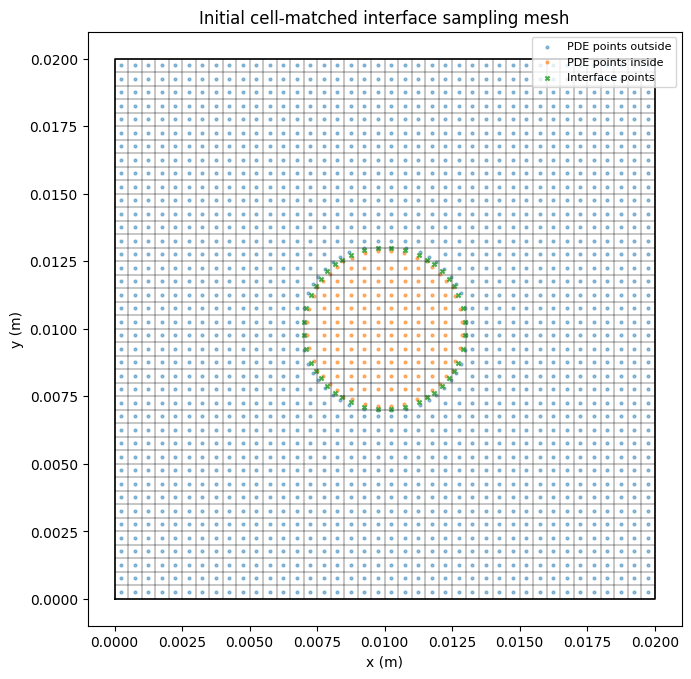

✅ 网格数据导出完成 | 文件夹：origin_adaptive_data原\00_initial_cell_matched_mesh


'origin_adaptive_data原\\00_initial_cell_matched_mesh'

In [20]:
EXPORT_ROOT = "origin_adaptive_data原"
os.makedirs(EXPORT_ROOT, exist_ok=True)

# 只生成背景 leaf cells，不再整条界面独立采样
all_cells = build_initial_cells(params, nx0=40, ny0=40)

# 根据界面 cell 规则生成 PDE 点和界面点
out_sample, in_sample, interface_sample, out_cells, in_cells = sample_points_from_matched_cells(all_cells, params, device)

x_dom_out, y_dom_out = out_sample["x"], out_sample["y"]
x_dom_in, y_dom_in = in_sample["x"], in_sample["y"]
x_if, y_if = interface_sample["x"], interface_sample["y"]

x_out_phys, y_out_phys = out_sample["x_phys"], out_sample["y_phys"]
x_in_phys, y_in_phys = in_sample["x_phys"], in_sample["y_phys"]
x_if_phys, y_if_phys = interface_sample["x_phys"], interface_sample["y_phys"]

plot_adaptive_sampling_circle(
    out_cells, in_cells, out_sample, in_sample, interface_sample, params,
    title="Initial cell-matched interface sampling mesh",
    save_path="sampling_mesh_initial_cell_matched.png",
)

export_mesh_data_to_folder(
    save_root=EXPORT_ROOT,
    round_label="00_initial_cell_matched_mesh",
    out_cells=out_cells,
    in_cells=in_cells,
    out_sample=out_sample,
    in_sample=in_sample,
    interface_sample=interface_sample,
)

In [4]:
def calc_rel_l2(pred, true):
    numerator = np.linalg.norm(pred - true, ord=2)
    denominator = np.linalg.norm(true, ord=2)
    return 0.0 if denominator < 1e-12 else numerator / denominator

def load_data_simple_full_nd(file_path):
    data = np.loadtxt(file_path, skiprows=1, usecols=range(5), delimiter=",")
    print(f"✅ 成功读取数据: {data.shape[0]} 行，{data.shape[1]} 列")
    return data

def fenlei(data_vals_nd, params):
    L, V_0, P_0 = params["L"], params["V_0"], params["P_0"]
    xc, yc, R = params["xc"], params["yc"], params["R"]
    x, y = data_vals_nd[:, 0], data_vals_nd[:, 1]
    rr = np.sqrt((x - xc) ** 2 + (y - yc) ** 2)
    tol = 2e-5
    mask_in = rr < R - tol
    mask_out = rr >= R
    inside_phys = data_vals_nd[mask_in]
    outside_phys = data_vals_nd[mask_out]

    def to_nd(arr):
        out = arr.copy()
        out[:, 0] = arr[:, 0] / L * 2.0 - 1.0
        out[:, 1] = arr[:, 1] / L * 2.0 - 1.0
        out[:, 2] = arr[:, 2] / V_0
        out[:, 3] = arr[:, 3] / V_0
        out[:, 4] = arr[:, 4] / P_0
        return out

    return inside_phys, outside_phys, to_nd(inside_phys), to_nd(outside_phys)

@torch.no_grad()
def predict_regions(net_out, net_in, inside_coords, outside_coords, params):
    uo, vo, po = forward_with_hard_bc(net_out, outside_coords, params)
    ui, vi, pi = forward_inside_free(net_in, inside_coords)
    return {
        "pred_out": torch.cat([uo, vo, po], dim=1).cpu().numpy(),
        "pred_in": torch.cat([ui, vi, pi], dim=1).cpu().numpy(),
        "true_out": outside_uvp.cpu().numpy(),
        "true_in": inside_uvp.cpu().numpy(),
        "coords_out": outside_coords.cpu().numpy(),
        "coords_in": inside_coords.cpu().numpy(),
    }


FEM_FILE = "com.csv"
HAS_FEM_DATA = os.path.exists(FEM_FILE)

if HAS_FEM_DATA:
    data_vals = load_data_simple_full_nd(FEM_FILE)
    inside_phys, outside_phys, inside_nd, outside_nd = fenlei(data_vals, params)
    inside_coords = torch.tensor(inside_nd[:, :2], dtype=torch.get_default_dtype(), device=device)
    inside_uvp = torch.tensor(inside_nd[:, 2:], dtype=torch.get_default_dtype(), device=device)
    outside_coords = torch.tensor(outside_nd[:, :2], dtype=torch.get_default_dtype(), device=device)
    outside_uvp = torch.tensor(outside_nd[:, 2:], dtype=torch.get_default_dtype(), device=device)
    print(f"孔内坐标形状：{inside_coords.shape}，孔外坐标形状：{outside_coords.shape}")

[Adam] iter=     0, PDE-out=1.62e+01, PDE-in=8.83e+01, IF=3.84e+01 (u_n=6.22e-01, jump_x=1.83e+01, jump_y=1.96e+01)
[Adam-L2] u=4.889284, v=0.706112, p=0.282158
[Adam] iter=   100, PDE-out=8.57e+00, PDE-in=5.29e-01, IF=3.62e-01 (u_n=1.40e-01, jump_x=8.38e-02, jump_y=1.39e-01)
[Adam-L2] u=1.110387, v=1.968584, p=0.416658
[Adam] iter=   200, PDE-out=3.05e+00, PDE-in=6.41e-02, IF=1.20e-01 (u_n=5.12e-02, jump_x=2.68e-02, jump_y=4.18e-02)
[Adam-L2] u=1.165085, v=1.587956, p=0.273312
[Adam] iter=   300, PDE-out=1.41e+00, PDE-in=3.01e-02, IF=3.97e-02 (u_n=1.69e-02, jump_x=9.28e-03, jump_y=1.35e-02)
[Adam-L2] u=1.054525, v=1.184966, p=0.185953
[Adam] iter=   400, PDE-out=6.93e-01, PDE-in=1.96e-02, IF=1.46e-02 (u_n=6.54e-03, jump_x=3.61e-03, jump_y=4.44e-03)
[Adam-L2] u=0.974931, v=0.845162, p=0.125927
[Adam] iter=   500, PDE-out=3.34e-01, PDE-in=1.41e-02, IF=6.60e-03 (u_n=2.65e-03, jump_x=1.74e-03, jump_y=2.21e-03)
[Adam-L2] u=0.942564, v=0.602057, p=0.081958
[Adam] iter=   600, PDE-out=1.61e-

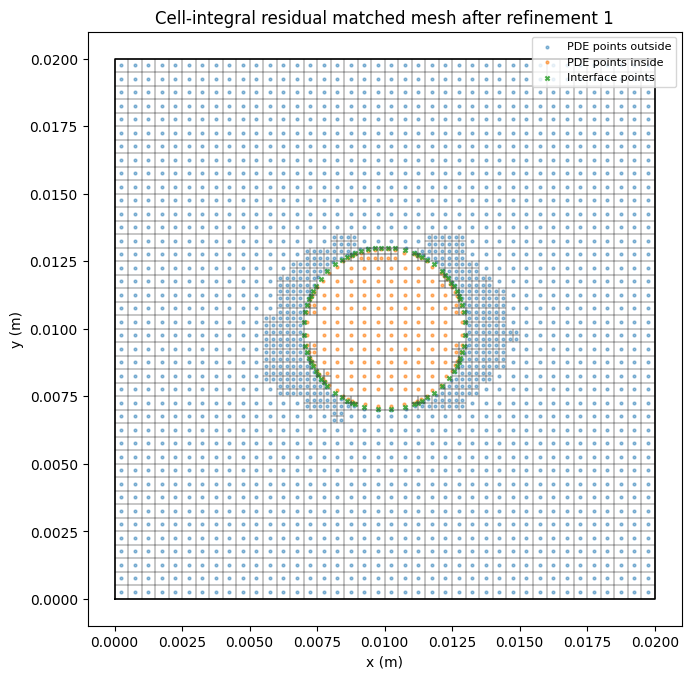

✅ 网格数据导出完成 | 文件夹：origin_adaptive_data原\cell_matched_refine_round_01
第 1 轮加密完成：统一加密 96 个 cell，2:1 平衡补加密 0 个 cell，界面点数量 71

[Adam] iter=  3000, PDE-out=1.85e-02, PDE-in=1.51e-03, IF=3.24e-03 (u_n=3.04e-05, jump_x=9.04e-04, jump_y=2.31e-03)
[Adam-L2] u=0.814888, v=0.225163, p=0.003171
[Adam] iter=  3100, PDE-out=1.89e-02, PDE-in=2.10e-03, IF=5.14e-03 (u_n=2.59e-05, jump_x=1.46e-03, jump_y=3.65e-03)
[Adam-L2] u=0.831504, v=0.236492, p=0.004422
[Adam] iter=  3200, PDE-out=1.84e-02, PDE-in=2.04e-03, IF=5.10e-03 (u_n=2.78e-05, jump_x=1.45e-03, jump_y=3.62e-03)
[Adam-L2] u=0.832574, v=0.237697, p=0.004308
[Adam] iter=  3300, PDE-out=1.81e-02, PDE-in=1.99e-03, IF=5.05e-03 (u_n=3.03e-05, jump_x=1.44e-03, jump_y=3.58e-03)
[Adam-L2] u=0.829602, v=0.237066, p=0.004260
[Adam] iter=  3400, PDE-out=1.78e-02, PDE-in=1.94e-03, IF=4.99e-03 (u_n=3.29e-05, jump_x=1.43e-03, jump_y=3.53e-03)
[Adam-L2] u=0.824465, v=0.235704, p=0.004219
[Adam] iter=  3500, PDE-out=1.76e-02, PDE-in=1.88e-03, IF=4.92e-03 (u_n=3

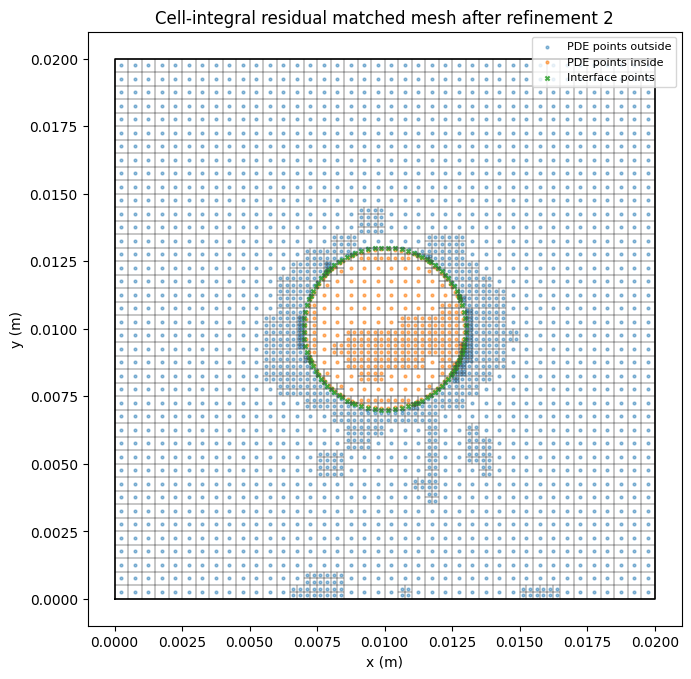

✅ 网格数据导出完成 | 文件夹：origin_adaptive_data原\cell_matched_refine_round_02
第 2 轮加密完成：统一加密 114 个 cell，2:1 平衡补加密 3 个 cell，界面点数量 105

[Adam] iter=  6000, PDE-out=9.48e-03, PDE-in=4.19e-04, IF=1.14e-03 (u_n=6.87e-05, jump_x=3.02e-04, jump_y=7.65e-04)
[Adam-L2] u=0.374501, v=0.110779, p=0.001937
[Adam] iter=  6100, PDE-out=1.02e-02, PDE-in=5.03e-04, IF=1.48e-03 (u_n=7.72e-05, jump_x=4.22e-04, jump_y=9.76e-04)
[Adam-L2] u=0.398896, v=0.118849, p=0.002184
[Adam] iter=  6200, PDE-out=9.54e-03, PDE-in=4.52e-04, IF=1.33e-03 (u_n=6.99e-05, jump_x=3.80e-04, jump_y=8.78e-04)
[Adam-L2] u=0.378889, v=0.113437, p=0.002051
[Adam] iter=  6300, PDE-out=9.63e-03, PDE-in=4.01e-04, IF=1.22e-03 (u_n=8.51e-05, jump_x=3.41e-04, jump_y=7.91e-04)
[Adam-L2] u=0.357710, v=0.106591, p=0.001886
[Adam] iter=  6400, PDE-out=8.45e-03, PDE-in=3.56e-04, IF=1.03e-03 (u_n=6.06e-05, jump_x=2.92e-04, jump_y=6.76e-04)
[Adam-L2] u=0.334795, v=0.100505, p=0.001781
[Adam] iter=  6500, PDE-out=8.82e-03, PDE-in=3.14e-04, IF=9.35e-04 (u_n

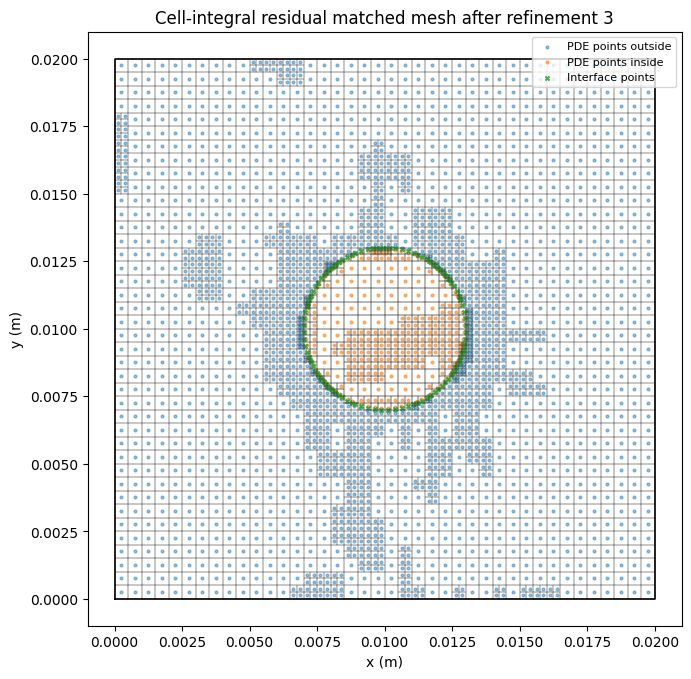

✅ 网格数据导出完成 | 文件夹：origin_adaptive_data原\cell_matched_refine_round_03
第 3 轮加密完成：统一加密 135 个 cell，2:1 平衡补加密 2 个 cell，界面点数量 127

[Adam] iter=  9000, PDE-out=2.20e-03, PDE-in=3.48e-05, IF=7.06e-05 (u_n=1.66e-05, jump_x=1.59e-05, jump_y=3.81e-05)
[Adam-L2] u=0.106904, v=0.026908, p=0.000420
[Adam] iter=  9100, PDE-out=2.57e-03, PDE-in=3.64e-05, IF=7.39e-05 (u_n=1.72e-05, jump_x=1.68e-05, jump_y=3.99e-05)
[Adam-L2] u=0.111569, v=0.027177, p=0.000485
[Adam] iter=  9200, PDE-out=2.45e-03, PDE-in=3.49e-05, IF=7.10e-05 (u_n=1.67e-05, jump_x=1.60e-05, jump_y=3.82e-05)
[Adam-L2] u=0.109758, v=0.026857, p=0.000488
[Adam] iter=  9300, PDE-out=2.36e-03, PDE-in=3.31e-05, IF=6.83e-05 (u_n=1.64e-05, jump_x=1.53e-05, jump_y=3.66e-05)
[Adam-L2] u=0.108127, v=0.026442, p=0.000483
[Adam] iter=  9400, PDE-out=2.27e-03, PDE-in=3.13e-05, IF=6.53e-05 (u_n=1.60e-05, jump_x=1.45e-05, jump_y=3.47e-05)
[Adam-L2] u=0.106334, v=0.025957, p=0.000477
[Adam] iter=  9500, PDE-out=2.22e-03, PDE-in=3.05e-05, IF=7.46e-05 (u_n

In [22]:
global_step = 0
loss_history = {"step": [], "total": [], "pde_out": [], "pde_in": [], "if_T": [], "phase": []}
l2_error_history = {"step": [], "u_l2": [], "v_l2": [], "p_l2": []}

adam = torch.optim.Adam(list(net_out.parameters()) + list(net_in.parameters()), lr=1e-3, weight_decay=1e-6)
scheduler = torch.optim.lr_scheduler.StepLR(adam, step_size=10000, gamma=1.0)

num_iters_adam = 10001
log_every = 100
refine_start = 2001
refine_every = 3000
max_refine_rounds =3
mark_ratio = 0.06
max_refine_level =3
area_n_side = 10
refine_round = 0

time_start = time.time()

for it in range(num_iters_adam + 1):
    adam.zero_grad()
    train_points = make_training_points()
    total_loss, loss_dict = compute_total_loss(train_points, params)
    total_loss.backward()
    adam.step()
    scheduler.step()
    global_step += 1

    # ====== 统一 cell 残差加密：普通 cell 和界面 cell 放在一起比较 ======
    if it >= refine_start and it % refine_every == 0 and refine_round < max_refine_rounds and it > 0:
        print("\n" + "=" * 70)
        print(f"开始第 {refine_round + 1} 轮自适应加密：Adam iter = {it}")
        print("=" * 70)

        all_cells, refined_count, stats = refine_cells_by_integral_residual(
            cells=all_cells,
            params=params,
            device=device,
            mark_ratio=mark_ratio,
            max_level=max_refine_level,
            lambda_gamma=LAMBDA_GAMMA,
            area_n_side=area_n_side,
        )

        all_cells, balance_refined = balance_cells_2to1(all_cells, params=params, max_level=max_refine_level)

        # 加密后重新识别界面 cell，并重新生成区域点和界面点
        out_sample, in_sample, interface_sample, out_cells, in_cells = sample_points_from_matched_cells(all_cells, params, device)
        x_dom_out, y_dom_out = out_sample["x"], out_sample["y"]
        x_dom_in, y_dom_in = in_sample["x"], in_sample["y"]
        x_if, y_if = interface_sample["x"], interface_sample["y"]
        x_out_phys, y_out_phys = out_sample["x_phys"], out_sample["y_phys"]
        x_in_phys, y_in_phys = in_sample["x_phys"], in_sample["y_phys"]
        x_if_phys, y_if_phys = interface_sample["x_phys"], interface_sample["y_phys"]

        refine_round += 1

        plot_adaptive_sampling_circle(
            out_cells, in_cells, out_sample, in_sample, interface_sample, params,
            title=f"Cell-integral residual matched mesh after refinement {refine_round}",
            save_path=f"sampling_mesh_cell_matched_refine_{refine_round}.png",
        )
        export_mesh_data_to_folder(
            save_root=EXPORT_ROOT,
            round_label=f"cell_matched_refine_round_{refine_round:02d}",
            out_cells=out_cells,
            in_cells=in_cells,
            out_sample=out_sample,
            in_sample=in_sample,
            interface_sample=interface_sample,
        )

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        print(f"第 {refine_round} 轮加密完成：统一加密 {refined_count} 个 cell，2:1 平衡补加密 {balance_refined} 个 cell，界面点数量 {len(x_if_phys)}")
        print("=" * 70 + "\n")

    if it % log_every == 0:
        loss_history["step"].append(global_step)
        loss_history["total"].append(total_loss.item())
        loss_history["pde_out"].append(loss_dict["L_pde_out"])
        loss_history["pde_in"].append(loss_dict["L_pde_in"])
        loss_history["if_T"].append(loss_dict["L_if_total"])
        loss_history["phase"].append("adam")

        print(
            f"[Adam] iter={it:6d}, "
            f"PDE-out={loss_dict['L_pde_out']:.2e}, "
            f"PDE-in={loss_dict['L_pde_in']:.2e}, "
            f"IF={loss_dict['L_if_total']:.2e} "
            f"(u_n={loss_dict['L_if_u_n']:.2e}, jump_x={loss_dict['loss_jump_x']:.2e}, jump_y={loss_dict['loss_jump_y']:.2e})"
        )

        if HAS_FEM_DATA:
            with torch.no_grad():
                pred = predict_regions(net_out, net_in, inside_coords, outside_coords, params)
                pred_u = np.concatenate([pred["pred_out"][:, 0], pred["pred_in"][:, 0]])
                pred_v = np.concatenate([pred["pred_out"][:, 1], pred["pred_in"][:, 1]])
                pred_p = np.concatenate([pred["pred_out"][:, 2], pred["pred_in"][:, 2]])
                true_u = np.concatenate([pred["true_out"][:, 0], pred["true_in"][:, 0]])
                true_v = np.concatenate([pred["true_out"][:, 1], pred["true_in"][:, 1]])
                true_p = np.concatenate([pred["true_out"][:, 2], pred["true_in"][:, 2]])
                u_l2, v_l2, p_l2 = calc_rel_l2(pred_u, true_u), calc_rel_l2(pred_v, true_v), calc_rel_l2(pred_p, true_p)
                l2_error_history["step"].append(it)
                l2_error_history["u_l2"].append(u_l2)
                l2_error_history["v_l2"].append(v_l2)
                l2_error_history["p_l2"].append(p_l2)
                print(f"[Adam-L2] u={u_l2:.6f}, v={v_l2:.6f}, p={p_l2:.6f}")

print(f"Total Adam time: {time.time() - time_start:.2f} s")

In [23]:
data_lbfgs = make_training_points()

lbfgs = torch.optim.LBFGS(
    params=list(net_out.parameters()) + list(net_in.parameters()),
    lr=1.0,
    max_iter=50,
    max_eval=None,
    tolerance_grad=1e-7,
    tolerance_change=1e-10,
    history_size=50,
    line_search_fn="strong_wolfe",
)

num_iters_lbfgs = 500

print("\n====== Start L-BFGS refinement ======\n")


def closure():
    global global_step

    # 清空梯度
    lbfgs.zero_grad()

    # 计算总损失
    total_loss, loss_dict = compute_total_loss(
        data_lbfgs,
        params
    )

    # 反向传播
    total_loss.backward()

    # 注意：L-BFGS在一次step中可能多次调用closure
    global_step += 1

    # 记录损失
    loss_history["step"].append(global_step)
    loss_history["total"].append(total_loss.item())
    loss_history["pde_out"].append(loss_dict["L_pde_out"])
    loss_history["pde_in"].append(loss_dict["L_pde_in"])
    loss_history["if_T"].append(loss_dict["L_if_total"])
    loss_history["phase"].append("lbfgs")

    # 每100次closure调用打印一次
    if global_step % 100 == 0:

        print(
            f"[L-BFGS] iter={global_step:6d}, "
            f"PDE-out={loss_dict['L_pde_out']:.2e}, "
            f"PDE-in={loss_dict['L_pde_in']:.2e}, "
            f"IF={loss_dict['L_if_total']:.2e}" )

        # FEM数据只用于误差评价，不参与损失
        if HAS_FEM_DATA:

            with torch.no_grad():

                pred_results = predict_regions(
                    net_out,
                    net_in,
                    inside_coords,
                    outside_coords,
                    params )

                # 预测值
                pred_u = np.concatenate([
                    pred_results["pred_out"][:, 0],
                    pred_results["pred_in"][:, 0]])

                pred_v = np.concatenate([
                    pred_results["pred_out"][:, 1],
                    pred_results["pred_in"][:, 1]])

                pred_p = np.concatenate([
                    pred_results["pred_out"][:, 2],
                    pred_results["pred_in"][:, 2]])

                # 真实值
                true_u = np.concatenate([
                    pred_results["true_out"][:, 0],
                    pred_results["true_in"][:, 0]])

                true_v = np.concatenate([
                    pred_results["true_out"][:, 1],
                    pred_results["true_in"][:, 1]])

                true_p = np.concatenate([
                    pred_results["true_out"][:, 2],
                    pred_results["true_in"][:, 2]])

                # 相对L2误差
                u_l2 = calc_rel_l2(pred_u, true_u)
                v_l2 = calc_rel_l2(pred_v, true_v)
                p_l2 = calc_rel_l2(pred_p, true_p)

                # 保存误差历史
                l2_error_history["step"].append(global_step)
                l2_error_history["u_l2"].append(u_l2)
                l2_error_history["v_l2"].append(v_l2)
                l2_error_history["p_l2"].append(p_l2)

                print(
                    f"[L-BFGS-L2] iter={global_step:6d}, "
                    f"u_L2={u_l2:.6f}, "
                    f"v_L2={v_l2:.6f}, "
                    f"p_L2={p_l2:.6f}"
                )

    # closure必须返回损失张量
    return total_loss


# 开始L-BFGS优化
for it in range(num_iters_lbfgs):

    lbfgs.step(closure)

    if (it + 1) % 10 == 0:
        print(
            f"L-BFGS outer step: "
            f"{it + 1}/{num_iters_lbfgs}"
        )


====== Start L-BFGS refinement ======

[L-BFGS] iter= 10100, PDE-out=1.24e-03, PDE-in=1.10e-05, IF=2.46e-05
[L-BFGS-L2] iter= 10100, u_L2=0.072793, v_L2=0.015342, p_L2=0.000282
[L-BFGS] iter= 10200, PDE-out=8.78e-04, PDE-in=8.02e-06, IF=1.61e-05
[L-BFGS-L2] iter= 10200, u_L2=0.062600, v_L2=0.011686, p_L2=0.000209
[L-BFGS] iter= 10300, PDE-out=6.57e-04, PDE-in=5.27e-06, IF=9.53e-06
[L-BFGS-L2] iter= 10300, u_L2=0.058261, v_L2=0.010033, p_L2=0.000139
[L-BFGS] iter= 10400, PDE-out=5.08e-04, PDE-in=4.19e-06, IF=6.38e-06
[L-BFGS-L2] iter= 10400, u_L2=0.051155, v_L2=0.008982, p_L2=0.000084
[L-BFGS] iter= 10500, PDE-out=4.08e-04, PDE-in=3.03e-06, IF=5.14e-06
[L-BFGS-L2] iter= 10500, u_L2=0.043816, v_L2=0.008124, p_L2=0.000086
L-BFGS outer step: 10/500
[L-BFGS] iter= 10600, PDE-out=3.39e-04, PDE-in=2.76e-06, IF=4.82e-06
[L-BFGS-L2] iter= 10600, u_L2=0.039788, v_L2=0.007468, p_L2=0.000085
[L-BFGS] iter= 10700, PDE-out=2.76e-04, PDE-in=2.21e-06, IF=3.92e-06
[L-BFGS-L2] iter= 10700, u_L2=0.03302

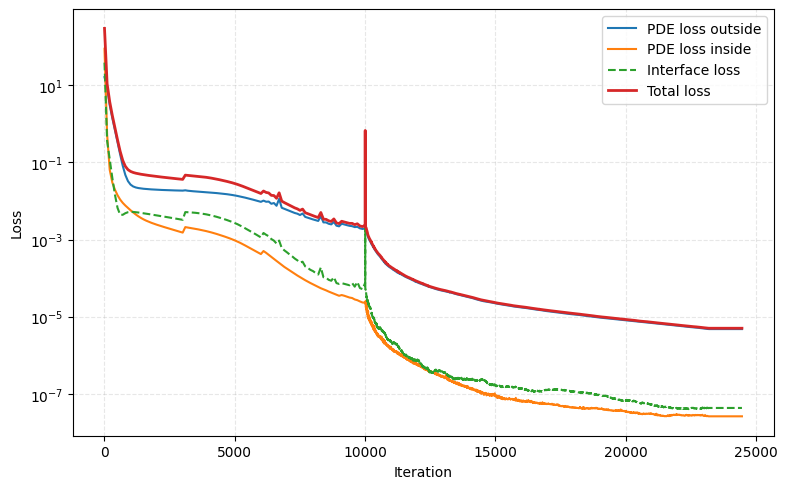

损失函数已保存到：loss_history.csv
L2误差已保存到：loss_l2.csv


In [24]:
def plot_loss_curves(loss_history):
    steps = np.asarray(loss_history["step"])
    plt.figure(figsize=(8, 5))
    plt.semilogy(steps, loss_history["pde_out"], label="PDE loss outside")
    plt.semilogy(steps, loss_history["pde_in"], label="PDE loss inside")
    plt.semilogy(steps, loss_history["if_T"], label="Interface loss", linestyle="--")
    plt.semilogy(steps, loss_history["total"], label="Total loss", linewidth=2)
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, which="both", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_loss_curves(loss_history)
pd.DataFrame(loss_history).to_csv("loss_history.csv", index=False)
print("损失函数已保存到：loss_history.csv")

if len(l2_error_history["step"]) > 0:
    pd.DataFrame(l2_error_history).to_csv("loss_l2.csv", index=False)
    print("L2误差已保存到：loss_l2.csv")

In [25]:
def calc_phys_and_error(pred_results, params):
    L, V_0, P_0 = params["L"], params["V_0"], params["P_0"]

    def process(coords_star, pred_star, true_star, tag):
        x_phys = (coords_star[:, 0] + 1.0) * 0.5 * L
        y_phys = (coords_star[:, 1] + 1.0) * 0.5 * L
        u_pred, v_pred, p_pred = pred_star[:, 0] * V_0, pred_star[:, 1] * V_0, pred_star[:, 2] * P_0
        u_true, v_true, p_true = true_star[:, 0] * V_0, true_star[:, 1] * V_0, true_star[:, 2] * P_0
        return pd.DataFrame({
            "x": x_phys, "y": y_phys,
            "u_pred": u_pred, "v_pred": v_pred, "p_pred": p_pred,
            "u_true": u_true, "v_true": v_true, "p_true": p_true,
            "u_err_abs": np.abs(u_pred - u_true),
            "v_err_abs": np.abs(v_pred - v_true),
            "p_err_abs": np.abs(p_pred - p_true),
            "region": tag,
        })

    df_out = process(pred_results["coords_out"], pred_results["pred_out"], pred_results["true_out"], "outside")
    df_in = process(pred_results["coords_in"], pred_results["pred_in"], pred_results["true_in"], "inside")
    df_all = pd.concat([df_out, df_in], ignore_index=True)

    print("\n===== 全域整体L2误差 =====")
    print(f"u: {calc_rel_l2(df_all['u_pred'].values, df_all['u_true'].values):.6f}")
    print(f"v: {calc_rel_l2(df_all['v_pred'].values, df_all['v_true'].values):.6f}")
    print(f"p: {calc_rel_l2(df_all['p_pred'].values, df_all['p_true'].values):.6f}")
    return df_all


if HAS_FEM_DATA:
    pred_results = predict_regions(net_out, net_in, inside_coords, outside_coords, params)
    df_all = calc_phys_and_error(pred_results, params)
    df_all.to_csv("total_pred1.csv", index=False, encoding="utf-8")
    print("预测结果与误差已保存到：total_pred1.csv")
else:
    print("未读取 FEM/COMSOL 数据，跳过误差数据保存。")


===== 全域整体L2误差 =====
u: 0.009942
v: 0.002269
p: 0.000008
预测结果与误差已保存到：total_pred1.csv


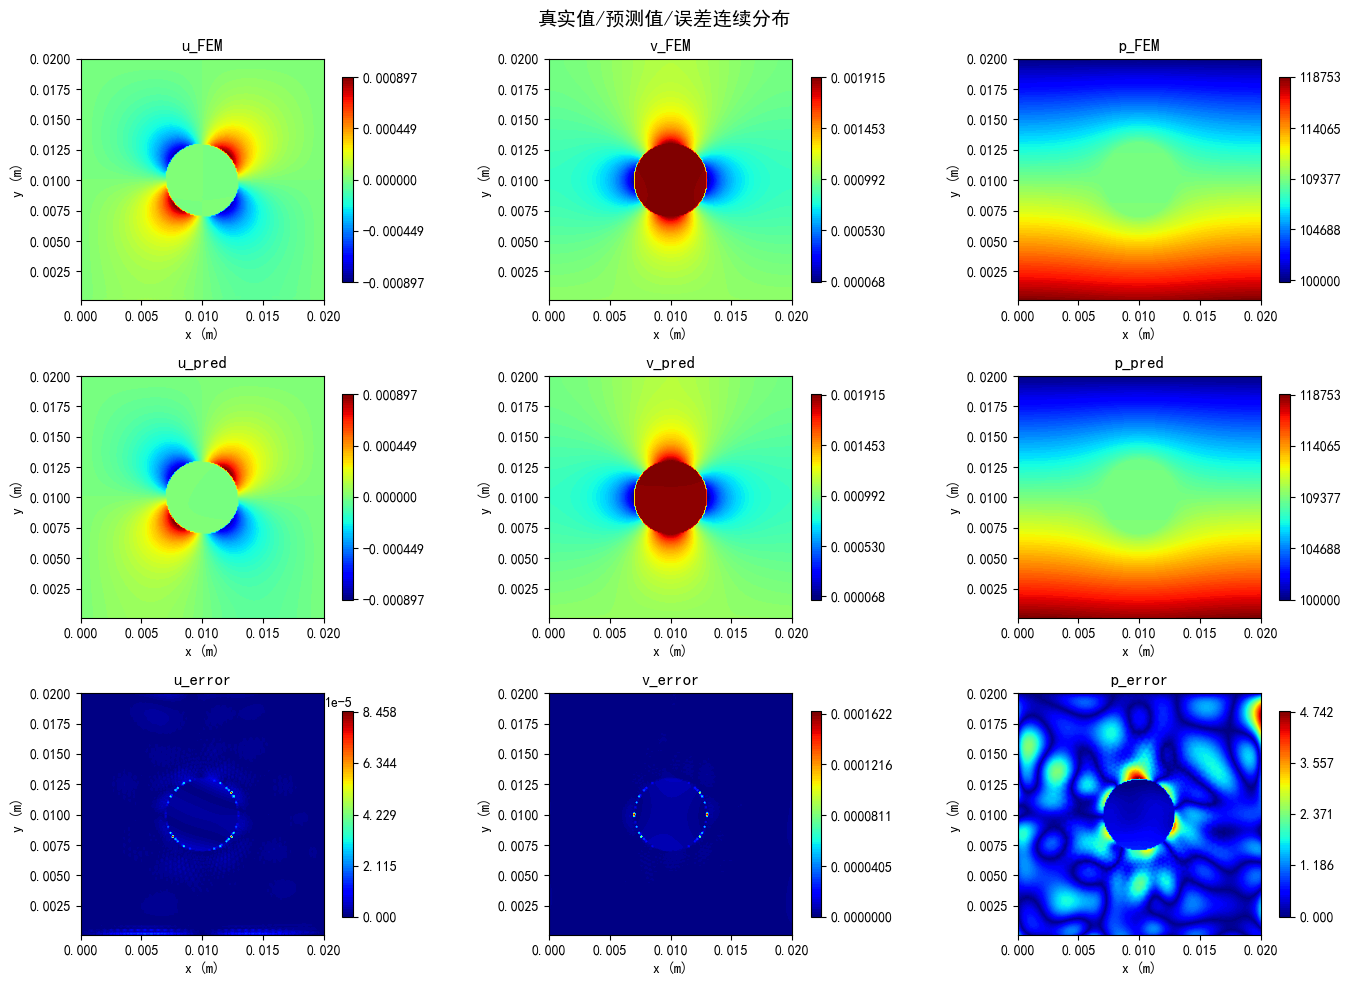

In [26]:
# 3×3 云图：真实值 / 预测值 / 误差
if HAS_FEM_DATA and os.path.exists("total_pred1.csv"):
    plt.rcParams["font.sans-serif"] = ["SimHei"]
    plt.rcParams["axes.unicode_minus"] = False

    df = pd.read_csv("total_pred1.csv", encoding="utf-8")

    fig, axes = plt.subplots(3, 3, figsize=(14, 10))
    fig.suptitle("真实值/预测值/误差连续分布", fontsize=14)

    dims = ["u", "v", "p"]
    titles = [
        ["u_FEM", "v_FEM", "p_FEM"],
        ["u_pred", "v_pred", "p_pred"],
        ["u_error", "v_error", "p_error"],
    ]

    # FEM 和预测共用 FEM 色标，误差单独色标
    fem_ranges = {}
    for col_idx, dim in enumerate(dims):
        true_val = df[f"{dim}_true"].values
        fem_ranges[col_idx] = (np.nanmin(true_val), np.nanmax(true_val))

    for row in range(3):
        for col in range(3):
            ax = axes[row, col]
            dim = dims[col]

            x = df["x"].values
            y = df["y"].values

            if row == 0:
                val = df[f"{dim}_true"].values
            elif row == 1:
                val = df[f"{dim}_pred"].values
            else:
                val = df[f"{dim}_err_abs"].values

            if row != 2:
                vmin, vmax = fem_ranges[col]
            else:
                vmin = np.nanmin(val)
                vmax = np.nanmax(val)

            ticks = np.linspace(vmin, vmax, 5)
            cntr = ax.tricontourf(x, y, val, levels=100, cmap="jet", vmin=vmin, vmax=vmax)
            fig.colorbar(cntr, ax=ax, shrink=0.85, ticks=ticks)

            ax.set_title(titles[row][col])
            ax.set_xlabel("x (m)")
            ax.set_ylabel("y (m)")
            ax.set_aspect("equal", adjustable="box")

    plt.tight_layout()
    plt.show()
else:
    print("未读取 FEM/COMSOL 数据，跳过 3×3 云图。")

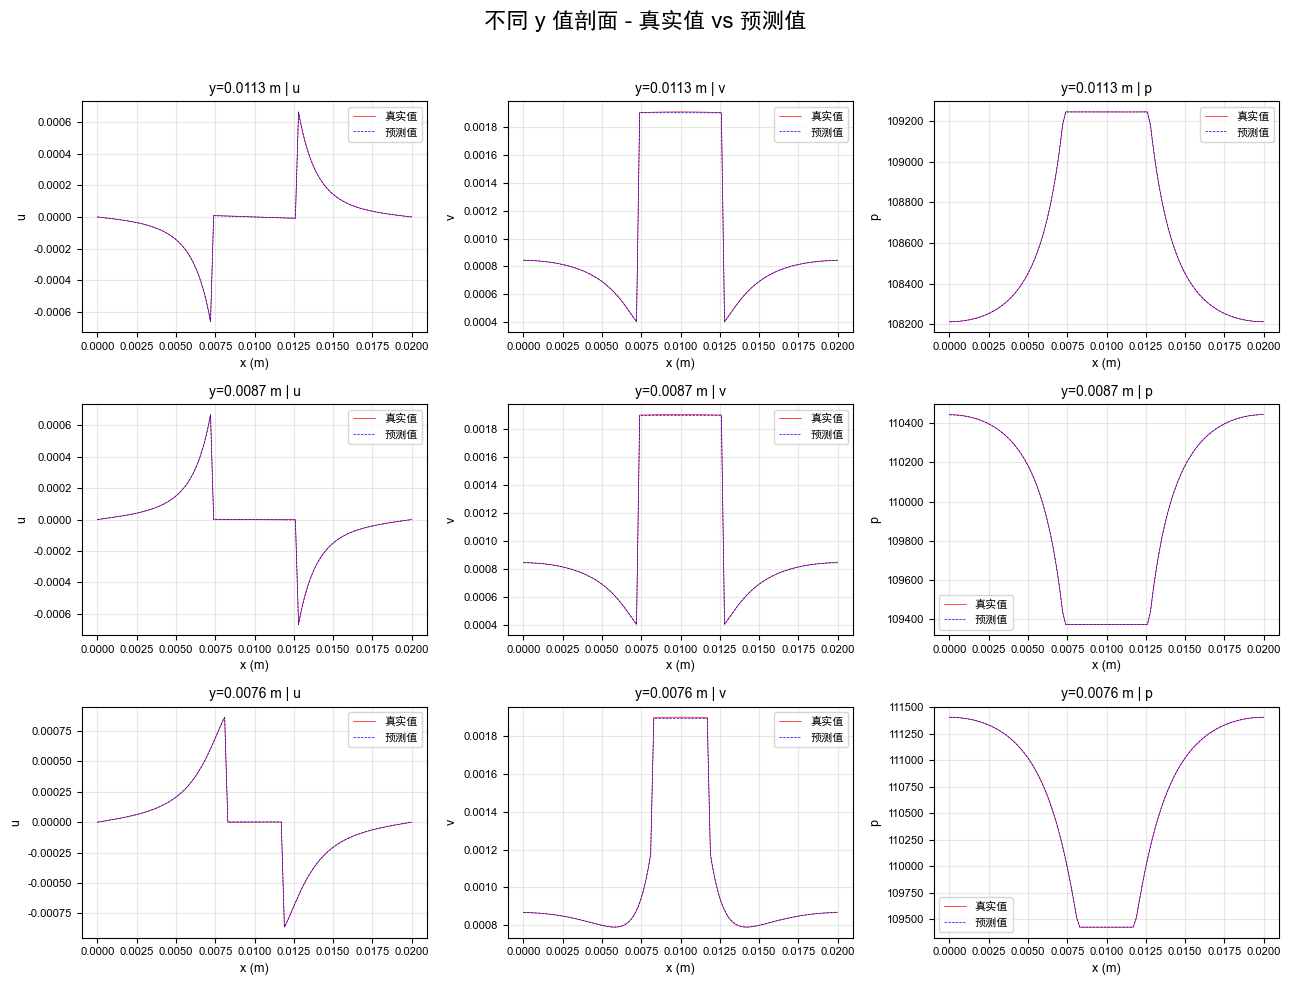

In [27]:
# 3×3 剖面线图
if HAS_FEM_DATA and os.path.exists("total_pred1.csv"):
    df = pd.read_csv("total_pred1.csv", encoding="utf-8")

    y_values = [0.0113, 0.0087, 0.0076]
    dims = ["u", "v", "p"]

    colors = {"true": "red", "pred": "blue"}
    styles = {"true": "-", "pred": "--"}

    plt.rcParams["font.family"] = ["Arial", "SimHei", "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    plt.rcParams["font.sans-serif"] = ["Arial", "SimHei"]

    fig, axes = plt.subplots(3, 3, figsize=(13, 10))
    fig.suptitle("不同 y 值剖面 - 真实值 vs 预测值", fontsize=16, y=0.98)

    for row, y_val in enumerate(y_values):
        for col, dim in enumerate(dims):
            ax = axes[row, col]
            df_slice = df[np.isclose(df["y"], y_val, atol=1e-5)].sort_values(by="x")

            ax.plot(df_slice["x"], df_slice[f"{dim}_true"],
                    color=colors["true"], linestyle=styles["true"],
                    label="真实值", linewidth=0.5)

            ax.plot(df_slice["x"], df_slice[f"{dim}_pred"],
                    color=colors["pred"], linestyle=styles["pred"],
                    label="预测值", linewidth=0.5)

            ax.set_title(f"y={y_val} m | {dim}", fontsize=10)
            ax.set_xlabel("x (m)", fontsize=9)
            ax.set_ylabel(f"{dim}", fontsize=9)
            ax.legend(loc="best", fontsize=8)
            ax.grid(alpha=0.3)
            ax.tick_params(axis="both", labelsize=8)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()
else:
    print("未读取 FEM/COMSOL 数据，跳过剖面线图。")